<a href="https://colab.research.google.com/github/tithisorker187/Biostatistics-lab/blob/main/DataMIningTithi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Problem 1 :

Perform Complete Data Preprocessing on a Simulated Dataset Using Python. Create a simulated dataset and implement the following data preprocessing steps:

   1.Dataset creation

   2.Dataset exploration

   3.Missing value analysis and handling

   4.Outlier detection and treatment using IQR

   5.Data transformation using binning

   6.Categorical variable encoding

   7.Feature engineering


   8.Feature selection using Chi-square test

   9.Feature scaling (Normalization and Standardization)

 10.Train-test split for machine learning










##Required Libraries :
The following Python libraries are used to perform the data preprocessing tasks:

##Pandas:
 For creating and manipulating datasets.

##NumPy:
 For numerical operations and handling missing values.

##Scikit-learn:
For label encoding, one-hot encoding, feature selection, feature scaling, and splitting the dataset into training and testing sets.

**Import Libraries and create dataset**

In [ ]:
#solve 1
#Dataset creation
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:

np.random.seed(10)

df = pd.DataFrame({
    'Age': np.random.randint(18, 30, 100),
    'Study_Hours': np.random.randint(1, 10, 100),
    'Marks': np.random.randint(30, 100, 100),
    'Attendance': np.random.randint(50, 100, 100),
    'Gender': np.random.choice(['Male', 'Female'], 100),
    'Result': np.random.choice(['Pass', 'Fail'], 100)
})

print(df.head())

   Age  Study_Hours  Marks  Attendance Gender Result
0   27            4     88          83   Male   Fail
1   22            4     69          83   Male   Pass
2   18            2     79          84   Male   Pass
3   19            3     41          62   Male   Pass
4   29            6     51          94   Male   Pass


##2.Explore the Datasets:

Here data types,data shapes and characteristics are described

In [ ]:
print(df.shape)
print(df.dtypes)
print(df.describe())
print(df.describe(include='object'))

(100, 6)
Age             int64
Study_Hours     int64
Marks           int64
Attendance      int64
Gender         object
Result         object
dtype: object
              Age  Study_Hours       Marks  Attendance
count  100.000000   100.000000  100.000000  100.000000
mean    23.680000     4.730000   64.080000   73.250000
std      3.612213     2.650919   19.787599   13.173569
min     18.000000     1.000000   30.000000   51.000000
25%     20.000000     2.000000   49.000000   64.000000
50%     24.000000     5.000000   62.000000   71.500000
75%     27.000000     7.000000   79.250000   84.000000
max     29.000000     9.000000   99.000000   99.000000
       Gender Result
count     100    100
unique      2      2
top      Male   Fail
freq       56     50


##Missing Value analysis and visualize

In [ ]:
# Introduce missing values
df.loc[2, 'Age'] = np.nan
df.loc[5, 'Gender'] = np.nan

# Check missing values
print(df.isnull().sum())

# Imputation
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

print(df.isnull().sum())

# Missing value count and percentage
missing = pd.DataFrame({
    'Count': df.isnull().sum(),
    'Percentage': df.isnull().mean() * 100})
print(missing)


Age            1
Study_Hours    0
Marks          0
Attendance     0
Gender         1
Result         0
dtype: int64
Age            0
Study_Hours    0
Marks          0
Attendance     0
Gender         0
Result         0
dtype: int64
             Count  Percentage
Age              0         0.0
Study_Hours      0         0.0
Marks            0         0.0
Attendance       0         0.0
Gender           0         0.0
Result           0         0.0


##4.Detecting and treat Outliers

In [ ]:
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Detect outliers
print(df[(df['Marks'] < lower) | (df['Marks'] > upper)])

# Treat outliers
df['Marks'] = df['Marks'].clip(lower, upper)

Empty DataFrame
Columns: [Age, Study_Hours, Marks, Attendance, Gender, Result]
Index: []


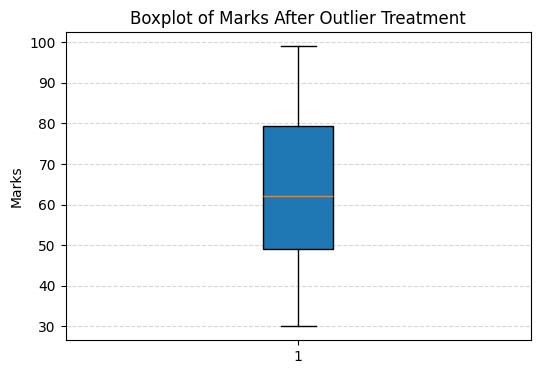

In [ ]:
# Plot after outlier treatment
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.boxplot(df['Marks'], patch_artist=True)
plt.title('Boxplot of Marks After Outlier Treatment')
plt.ylabel('Marks')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

##5.Data transformation using binning

In [ ]:
df['Study_Category'] = pd.cut(
    df['Study_Hours'],
    bins=[0, 3, 6, 10],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

print(df[['Study_Hours', 'Study_Category']].head())

   Study_Hours Study_Category
0            4         Medium
1            4         Medium
2            2            Low
3            3            Low
4            6         Medium


##6.categorical variable Encoding

In [ ]:
# Label Encoding
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])
df['Result'] = le.fit_transform(df['Result'])

# One-Hot Encoding
df = pd.get_dummies(
    df, columns=['Study_Category'], dtype=int
)

print(df.head())

    Age  Study_Hours  Marks  Attendance  Gender  Result  Study_Category_Low  \
0  27.0            4     88          83       1       0                   0   
1  22.0            4     69          83       1       1                   0   
2  24.0            2     79          84       1       1                   1   
3  19.0            3     41          62       1       1                   1   
4  29.0            6     51          94       1       1                   0   

   Study_Category_Medium  Study_Category_High  
0                      1                    0  
1                      1                    0  
2                      0                    0  
3                      0                    0  
4                      1                    0  


##7.Feature engineering

In [ ]:
df['Performance_Score'] = (
    df['Marks'] * 0.7 + df['Attendance'] * 0.3
)

print(df.head())

    Age  Study_Hours  Marks  Attendance  Gender  Result  Study_Category_Low  \
0  27.0            4     88          83       1       0                   0   
1  22.0            4     69          83       1       1                   0   
2  24.0            2     79          84       1       1                   1   
3  19.0            3     41          62       1       1                   1   
4  29.0            6     51          94       1       1                   0   

   Study_Category_Medium  Study_Category_High  Performance_Score  
0                      1                    0               86.5  
1                      1                    0               73.2  
2                      0                    0               80.5  
3                      0                    0               47.3  
4                      1                    0               63.9  


##.Prepare input features and target

In [ ]:
# Prepare input features and target
X = df.drop('Result', axis=1)
y = df['Result']

print("Input Features:\n", X.head())
print("Target:\n", y.head())

Input Features:
     Age  Study_Hours  Marks  Attendance  Gender  Study_Category_Low  \
0  27.0            4     88          83       1                   0   
1  22.0            4     69          83       1                   0   
2  24.0            2     79          84       1                   1   
3  19.0            3     41          62       1                   1   
4  29.0            6     51          94       1                   0   

   Study_Category_Medium  Study_Category_High  Performance_Score  
0                      1                    0               86.5  
1                      1                    0               73.2  
2                      0                    0               80.5  
3                      0                    0               47.3  
4                      1                    0               63.9  
Target:
 0    0
1    1
2    1
3    1
4    1
Name: Result, dtype: int64


##8.feature selection using chi sqare

In [ ]:
# Feature selection using Chi-square
selector = SelectKBest(score_func=chi2, k='all')
X_new = selector.fit_transform(X, y)

# Display scores
scores = pd.DataFrame({
    'Feature': X.columns,
    'Chi-Square Score': selector.scores_
})
print(scores.sort_values(by='Chi-Square Score', ascending=False))

                 Feature  Chi-Square Score
2                  Marks          5.169164
8      Performance_Score          4.248365
3             Attendance          2.562321
6  Study_Category_Medium          2.000000
5     Study_Category_Low          0.947368
1            Study_Hours          0.255814
7    Study_Category_High          0.133333
0                    Age          0.082561
4                 Gender          0.071429


In [ ]:
cols = ['Age', 'Study_Hours', 'Marks', 'Attendance', 'Performance_Score']

df_norm = df.copy()
df_norm[cols] = MinMaxScaler().fit_transform(df[cols])
print(df_norm.head())

df_std = df.copy()
df_std[cols] = StandardScaler().fit_transform(df[cols])
print(df_std.head())

        Age  Study_Hours     Marks  Attendance  Gender  Result  \
0  0.818182        0.375  0.840580    0.666667       1       0   
1  0.363636        0.375  0.565217    0.666667       1       1   
2  0.545455        0.125  0.710145    0.687500       1       1   
3  0.090909        0.250  0.159420    0.229167       1       1   
4  1.000000        0.625  0.304348    0.895833       1       1   

   Study_Category_Low  Study_Category_Medium  Study_Category_High  \
0                   0                      1                    0   
1                   0                      1                    0   
2                   1                      0                    0   
3                   1                      0                    0   
4                   0                      1                    0   

   Performance_Score  
0           0.858456  
1           0.613971  
2           0.748162  
3           0.137868  
4           0.443015  
        Age  Study_Hours     Marks  Attendance  Ge

##10.Train and Test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
X_train.head()

Training data: (70, 9)
Testing data: (30, 9)


,Age,Study_Hours,Marks,Attendance,Gender,Study_Category_Low,Study_Category_Medium,Study_Category_High,Performance_Score
73,23.0,6,87,96,0,0,1,0,89.7
6,18.0,2,78,96,1,1,0,0,83.4
3,19.0,3,41,62,1,1,0,0,47.3
27,19.0,6,71,79,0,0,1,0,73.4
51,26.0,7,32,97,1,0,0,1,51.5


##Problem 2 :